# Transformers: Attention, Pretraining & Finetuning (a mini GPT)

**The task:** answer questions like

> **Q:** Where was Khatchig Mouradian born? **A:** Lebanon

The 2,000 training examples contain *different* people from the test questions, so the answer can't be learned from the
task data alone — the model needs **world knowledge**. The story of this notebook:

1. **Attention from scratch** — what it computes and why multiple heads help
2. **A small GPT** (decoder-only Transformer), built from scratch in PyTorch
3. **Finetune without pretraining** → it fails (worse than always answering "London")
4. **Pretrain on Wikipedia text** with a *span corruption* objective, then finetune → much better
5. **Perceiver variant (bonus):** a cheaper attention that works on a shorter sequence

Everything works at the **character** level (each token is one character), which keeps the vocabulary tiny.

**Data:** put the `transformer_data` folder (or `transformer_data.zip`) next to this notebook. On Colab, upload the zip using the file panel and select a GPU.

In [ ]:
import os, math, time, random, zipfile
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
random.seed(0); torch.manual_seed(0)
print('Using device:', device)

# 1 · Attention from scratch

Given a **query** $q$ and $n$ (key, value) pairs $(k_i, v_i)$:

$$\alpha = \text{softmax}(k_1^\top q, \dots, k_n^\top q), \qquad c = \sum_i \alpha_i\, v_i$$

* $\alpha$ is a **probability distribution** (softmax outputs are positive and sum to 1) over the $n$ items.
* $c$ is a **weighted average of the values**, weighted by how well each key matches the query.

Three small experiments show what attention can and can't do easily.

In [ ]:
def attend(q, K, V):
    """q: (d,), K: (n, d), V: (n, d) -> weights (n,), output (d,)"""
    alpha = F.softmax(K @ q, dim=0)
    return alpha, alpha @ V

torch.manual_seed(0)
d = 4
K = torch.eye(d)               # 4 orthogonal unit keys
V = torch.randn(d, d)          # 4 random values

**Experiment 1 — copying.** Point the query at one key and make it large: $q = \beta k_2$.
As $\beta$ grows, the softmax becomes one-hot, so the output $c$ becomes almost exactly $v_2$. Attention can **copy** a value.

In [ ]:
for beta in [0.5, 2, 10, 50]:
    alpha, c = attend(beta * K[1], K, V)
    print(f'beta={beta:5}: alpha = {alpha.numpy().round(3)}   |c - v_2| = {(c - V[1]).norm():.4f}')

**Experiment 2 — averaging two items.** With $q = \beta(k_1 + k_3)$, keys 1 and 3 get equal, large scores, so $c \approx \tfrac12(v_1 + v_3)$.

In [ ]:
alpha, c = attend(20 * (K[0] + K[2]), K, V)
print('alpha =', alpha.numpy().round(3))
print('|c - (v_1 + v_3)/2| =', round((c - (V[0] + V[2]) / 2).norm().item(), 4))

**Experiment 3 — why multiple heads?** Real keys are noisy. Suppose $k_a$ points the right way but its *length* varies from
sample to sample (the red region below):

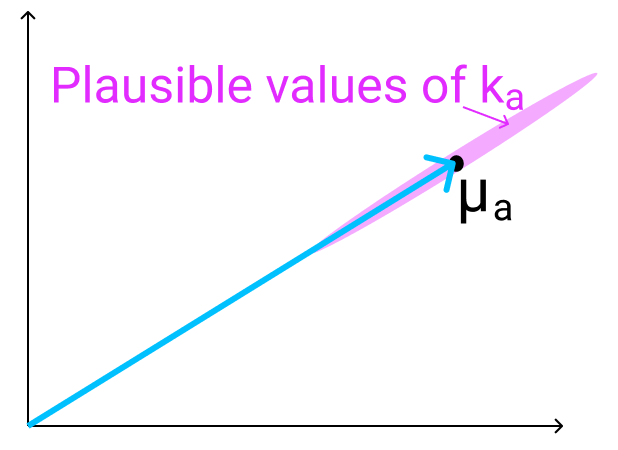

* **One head** with $q = \beta(k_a + k_b)$: whichever key happens to be longer wins the softmax, so the output jumps between $v_a$ and $v_b$.
* **Two heads**: head 1 uses $q_1 = \beta k_a$ (copies $v_a$), head 2 uses $q_2 = \beta k_b$ (copies $v_b$), and we average the heads. Each head only has to copy, which is robust, so the result is stably $\approx \tfrac12(v_a+v_b)$.

Below, "weight on $v_a$" is the fraction of the output that comes from $v_a$ (0.5 is the goal).

In [ ]:
beta = 20
for trial in range(5):
    Kn = K.clone(); Kn[0] *= random.uniform(0.5, 1.5)      # k_a with a random length
    one_head, _ = attend(beta * (K[0] + K[1]), Kn, V)
    head1, _ = attend(beta * K[0], Kn, V)
    head2, _ = attend(beta * K[1], Kn, V)
    two_heads = (head1 + head2) / 2
    print(f'|k_a| = {Kn[0].norm():.2f}   one head: weight on v_a = {one_head[0]:.2f}   two heads: {two_heads[0]:.2f}')

## Scaled dot-product self-attention, with a causal mask

In a Transformer, queries, keys and values all come from the same sequence $X \in \mathbb{R}^{\ell \times d}$ through learned matrices.
For one head:

$$Y = \text{softmax}\Big(\frac{(XQ)(XK)^\top}{\sqrt{d_{head}}} + \text{mask}\Big)(XV)$$

* Dividing by $\sqrt{d_{head}}$ keeps the dot products from growing with dimension, so the softmax doesn't saturate.
* **Multi-head:** run $h$ heads with $d_{head} = d/h$ in parallel, concatenate, and mix with a final linear layer.
* **Causal mask:** a language model predicts the *next* character, so position $i$ may only look at positions $\le i$.
  We set the scores above the diagonal to $-\infty$ (weight 0 after softmax):

In [ ]:
T = 8
mask = torch.ones(T, T).tril()
plt.figure(figsize=(3.5, 3.5)); plt.imshow(mask, cmap='Greens')
plt.title('causal mask (green = allowed)'); plt.xlabel('key position (attended to)'); plt.ylabel('query position'); plt.show()

# 2 · The data

* `wiki.txt` — one short Wikipedia-style paragraph per person (pretraining text, ~2,900 people)
* `birth_places_train.tsv` — 2,000 `question \t answer` pairs (finetuning)
* `birth_dev.tsv` — 500 pairs for evaluation, `birth_test_inputs.tsv` — questions only

In [ ]:
DATA_DIR = 'transformer_data'
if not os.path.isdir(DATA_DIR) and os.path.exists('transformer_data.zip'):
    with zipfile.ZipFile('transformer_data.zip') as z:
        z.extractall('.')
assert os.path.isdir(DATA_DIR), 'Put the transformer_data folder (or transformer_data.zip) next to this notebook.'

def read(name):
    with open(os.path.join(DATA_DIR, name), encoding='utf-8') as f:
        return f.read()

wiki_text = read('wiki.txt')
print(wiki_text[:300], '...\n')
print(read('birth_places_train.tsv')[:150])

**Character vocabulary.** Two special characters plus every character in `wiki.txt`:

| id | char | role |
|---|---|---|
| 0 | `□` | **PAD** — fills unused positions; the loss *ignores* it (`ignore_index=0`) |
| 1 | `⁇` | **MASK** — a separator / "something is missing here" marker |
| 2… | sorted characters | |

In [ ]:
PAD_CHAR, MASK_CHAR = '\u25A1', '\u2047'
chars = [PAD_CHAR, MASK_CHAR] + sorted(set(wiki_text))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
PAD_ID, MASK_ID, VOCAB_SIZE = 0, 1, len(chars)
BLOCK_SIZE = 128                       # max sequence length the model sees

def encode(s):
    return torch.tensor([stoi[c] for c in s], dtype=torch.long)

def decode(ids):
    return ''.join(itos[int(i)] for i in ids)

print('vocab size:', VOCAB_SIZE)

## Finetuning examples: question → answer

Each example becomes the string `question ⁇ answer ⁇ □□□…`, trained like a language model (predict the next character).

The trick is in the **targets**: everything up to the end of the question is replaced by PAD, which the loss ignores.
So the model is only trained to produce `⁇Lebanon⁇`, not to predict the question itself.

In [ ]:
class NameDataset(Dataset):
    def __init__(self, text):
        text = text.encode('utf-8').decode('ascii', errors='ignore')     # drop characters outside the vocab
        self.pairs = [line.split('\t') for line in text.split('\n') if '\t' in line]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        question, answer = self.pairs[idx]
        s = question + MASK_CHAR + answer + MASK_CHAR
        s = s + PAD_CHAR * (BLOCK_SIZE - len(s))
        x = s[:-1]                                           # input: everything but the last char
        y = PAD_CHAR * (len(question) - 1) + s[len(question):]   # target: shifted by one, question hidden
        return encode(x), encode(y)

finetune_data = NameDataset(read('birth_places_train.tsv'))
x, y = finetune_data[0]
print('x:', decode(x)[:60])
print('y:', decode(y)[:60])

# 3 · A small GPT

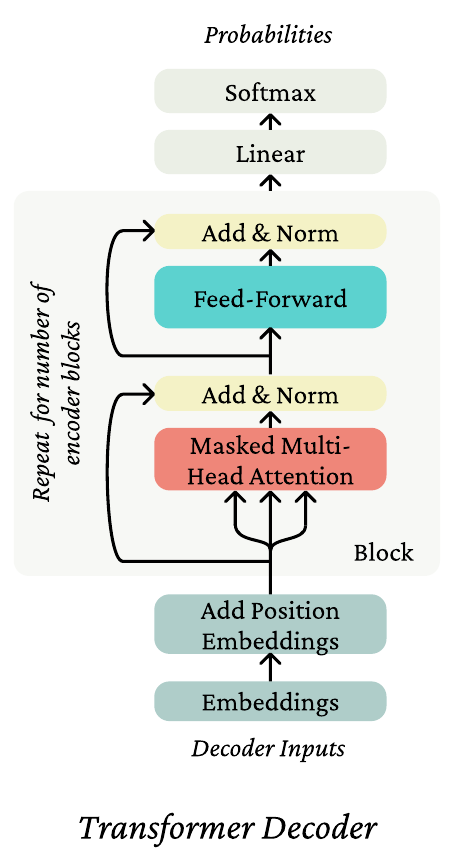

Each **block** = masked multi-head attention + a feed-forward MLP, each wrapped in a **residual connection** with **LayerNorm**.
We use the common *pre-norm* arrangement (`x + attn(LN(x))`), which is equivalent when blocks are stacked and trains more easily.

Input = token embedding + a **learned position embedding** (attention by itself has no idea of word order — without position
information, shuffling the input would just shuffle the output).

Our `Attention` module takes separate inputs for queries (`x_q`) and keys/values (`x_kv`):
`attn(x, x)` is ordinary **self**-attention; `attn(a, b)` is **cross**-attention, which we need for the Perceiver in Section 6.

In [ ]:
class Attention(nn.Module):
    def __init__(self, n_embd, n_head, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.query = nn.Linear(n_embd, n_embd)
        self.key = nn.Linear(n_embd, n_embd)
        self.value = nn.Linear(n_embd, n_embd)
        self.proj = nn.Linear(n_embd, n_embd)             # mixes the heads back together
        self.attn_drop, self.resid_drop = nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, x_q, x_kv):
        Tq, Tk, C = x_q.size(1), x_kv.size(1), x_q.size(2)
        hs = C // self.n_head
        # (B, T, C) -> (B, n_head, T, head_size): each head gets its own slice of the channels
        q = self.query(x_q).view(-1, Tq, self.n_head, hs).transpose(1, 2)
        k = self.key(x_kv).view(-1, Tk, self.n_head, hs).transpose(1, 2)
        v = self.value(x_kv).view(-1, Tk, self.n_head, hs).transpose(1, 2)
        att = q @ k.transpose(-2, -1) / math.sqrt(hs)       # (B, n_head, Tq, Tk) scores
        causal = torch.ones(Tq, Tk, dtype=torch.bool, device=att.device).tril()
        att = att.masked_fill(~causal, float('-inf'))       # no peeking at the future
        att = self.attn_drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).reshape(-1, Tq, C)    # concatenate the heads
        return self.resid_drop(self.proj(y))

def mlp(n_embd, dropout):
    return nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

class Block(nn.Module):
    def __init__(self, n_embd, n_head, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = Attention(n_embd, n_head, dropout)
        self.mlp = mlp(n_embd, dropout)

    def forward(self, x):
        h = self.ln1(x)
        x = x + self.attn(h, h)              # residual + self-attention
        x = x + self.mlp(self.ln2(x))        # residual + feed-forward
        return x

**Check:** our attention should match PyTorch's built-in `F.scaled_dot_product_attention` (with dropout off).

In [ ]:
attn = Attention(n_embd=16, n_head=4, dropout=0.0).eval()
xx = torch.randn(2, 5, 16)
q, k, v = (lin(xx).view(2, 5, 4, 4).transpose(1, 2) for lin in (attn.query, attn.key, attn.value))
ref = attn.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 5, 16))
print('max difference:', (attn(xx, xx) - ref).abs().max().item())

The full model. `bottleneck_dim` switches on the Perceiver variant (ignore it until Section 6; its two blocks are defined there).

In [ ]:
class GPT(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, block_size=BLOCK_SIZE, n_layer=4, n_head=8, n_embd=256,
                 dropout=0.1, bottleneck_dim=None):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Parameter(torch.zeros(1, block_size, n_embd))   # one learned vector per position
        self.drop = nn.Dropout(dropout)
        self.perceiver = bottleneck_dim is not None
        if self.perceiver:   # first and last blocks are replaced by down/up projections
            self.down = DownProjectBlock(n_embd, n_head, bottleneck_dim, dropout)
            self.blocks = nn.Sequential(*[Block(n_embd, n_head, dropout) for _ in range(n_layer - 2)])
            self.up = UpProjectBlock(n_embd, n_head, dropout)
        else:
            self.blocks = nn.Sequential(*[Block(n_embd, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)            # hidden -> next-character scores
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        t = idx.size(1)
        assert t <= self.block_size
        x_input = self.drop(self.tok_emb(idx) + self.pos_emb[:, :t])
        x = self.down(x_input) if self.perceiver else x_input
        x = self.blocks(x)
        if self.perceiver:
            x = self.up(x, x_input)
        logits = self.head(self.ln_f(x))                                 # (B, T, vocab)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=PAD_ID)
        return logits, loss

## Training loop

Standard GPT recipe (as in the assignment, which forks Karpathy's minGPT):
* **AdamW** with weight decay 0.1 on the weight matrices of linear layers only (not biases, LayerNorm, or embeddings).
* **Gradient clipping** at norm 1.0.
* **Cosine learning-rate decay** down to 10% of the starting value (reached after 200 pretraining-epochs' worth of tokens, then kept constant).
  Many setups also use a short *warmup*; in this configuration minGPT's warmup is shorter than a single batch, so we skip it.

In [ ]:
def train(model, dataset, epochs, batch_size, lr, n_pretrain_docs, print_every=10):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    decay = {id(m.weight) for m in model.modules() if isinstance(m, nn.Linear)}
    params = list(model.parameters())
    optimizer = torch.optim.AdamW([
        {'params': [p for p in params if id(p) in decay], 'weight_decay': 0.1},
        {'params': [p for p in params if id(p) not in decay], 'weight_decay': 0.0},
    ], lr=lr, betas=(0.9, 0.95))
    final_tokens = 200 * n_pretrain_docs * BLOCK_SIZE
    tokens_per_step = batch_size * BLOCK_SIZE
    def lr_factor(step):                                      # cosine from 1.0 down to 0.1, then flat
        progress = min(1.0, (step + 1) * tokens_per_step / final_tokens)
        return max(0.1, 0.5 * (1 + math.cos(math.pi * progress)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

    losses, start = [], time.time()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for x, y in loader:
            _, loss = model(x.to(device), y.to(device))
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(loader))
        if (epoch + 1) % print_every == 0 or epoch == 0:
            print(f'epoch {epoch + 1:4d}/{epochs}  loss {losses[-1]:.3f}  lr {scheduler.get_last_lr()[0]:.2e}  ({time.time() - start:.0f}s)')
    return losses

## Predicting and scoring

Feed `question⁇` and let the model write one character at a time (greedy: always the most likely next character)
until it writes the second `⁇`. Whatever is between the two `⁇` is the answer. Accuracy = exact string match.

In [ ]:
@torch.no_grad()
def predict_place(model, question, max_new=32):
    model.eval()
    x = encode(''.join(c for c in question if c in stoi) + MASK_CHAR)[None].to(device)
    for _ in range(max_new):
        logits, _ = model(x[:, -BLOCK_SIZE:])
        nxt = logits[0, -1].argmax()
        if nxt.item() == MASK_ID:
            break
        x = torch.cat([x, nxt.view(1, 1)], dim=1)
    return decode(x[0].tolist()).split(MASK_CHAR)[1]

def evaluate(model, file='birth_dev.tsv', show=0):
    pairs = [line.split('\t') for line in read(file).strip().split('\n')]
    preds = [predict_place(model, q) for q, _ in pairs]
    correct = sum(p == a for p, (_, a) in zip(preds, pairs))
    for (q, a), p in list(zip(pairs, preds))[:show]:
        print(f'{"✓" if p == a else "✗"} {q}  predicted: {p!r}  true: {a!r}')
    print(f'Accuracy: {correct}/{len(pairs)} = {100 * correct / len(pairs):.1f}%')
    return correct / len(pairs)

# 4 · Experiment 1: finetuning only (no pretraining)

Train a fresh model on the 2,000 question/answer pairs only (75 epochs, as in the assignment). A few minutes on a GPU.

In [ ]:
torch.manual_seed(0)
documents = [d for d in wiki_text.split('\n') if len(d) >= 4]
N_DOCS = len(documents)

scratch = GPT().to(device)
print(f'parameters: {sum(p.numel() for p in scratch.parameters()):,}')
_ = train(scratch, finetune_data, epochs=75, batch_size=256, lr=6e-4, n_pretrain_docs=N_DOCS, print_every=15)
acc_scratch = evaluate(scratch, show=5)

**Baseline:** what if we just always answered "London" (the most common birthplace)?

In [ ]:
dev_answers = [line.split('\t')[1] for line in read('birth_dev.tsv').strip().split('\n')]
acc_london = sum(a == 'London' for a in dev_answers) / len(dev_answers)
print(f'Always "London": {100 * acc_london:.1f}%')

The model from scratch does **worse than the London baseline** (the assignment's reference: about 2% vs 5%).
It learned the *format* (it outputs a place name) but has no way of knowing where people it has never read about were born.
The knowledge simply isn't in the training data.

# 5 · Experiment 2: pretrain, then finetune

**Pretraining** = train on lots of raw text with a self-supervised objective, so the model soaks up knowledge (here: the Wikipedia
sentences that mention where people were born). **Finetuning** = continue training on the small task dataset, so the model learns to *use*
that knowledge to answer questions.

## The pretraining objective: span corruption

A simplified version of T5's objective: cut out a random chunk of a document, move it to the end, and train the model to regenerate it.

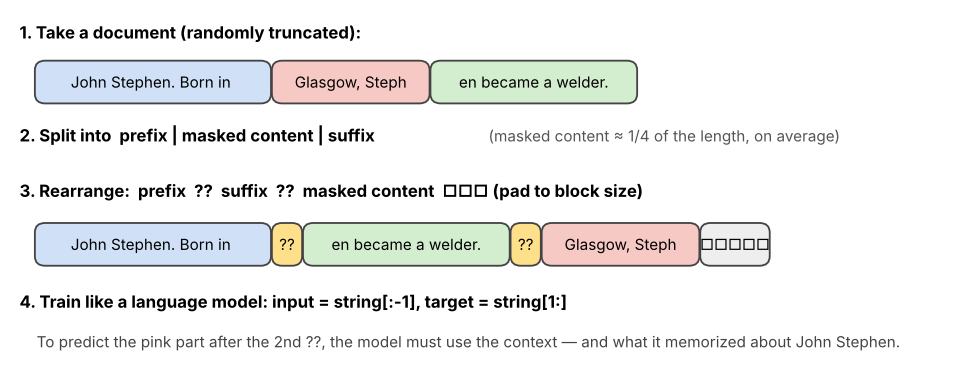

Because the finetuning format (`question ⁇ answer ⁇`) looks like this (`context ⁇ … ⁇ missing piece`), the model learns during pretraining
exactly the skill it needs later: *after a `⁇`, produce the missing fact from what you know*.

In [ ]:
class CharCorruptionDataset(Dataset):
    def __init__(self, documents):
        self.docs = documents

    def __len__(self):
        return len(self.docs)

    def __getitem__(self, idx):
        doc = self.docs[idx][:random.randint(4, int(BLOCK_SIZE * 7 / 8))]   # 1. random truncation
        n = len(doc)
        span = random.randint(1, max(1, n // 2))                            # 2. random span, ~n/4 on average
        start = random.randint(0, n - span)
        prefix, masked, suffix = doc[:start], doc[start:start + span], doc[start + span:]
        s = prefix + MASK_CHAR + suffix + MASK_CHAR + masked                # 3. rearrange
        s = s + PAD_CHAR * (BLOCK_SIZE + 1 - len(s))
        return encode(s[:-1]), encode(s[1:])                                # 4. next-character prediction

pretrain_data = CharCorruptionDataset(documents)
for i in range(3):
    x, y = pretrain_data[i]
    print('x:', decode(x).rstrip(PAD_CHAR))

## Pretrain

650 epochs over `wiki.txt` (as in the assignment). **This is the long one**: the assignment budgets about 2 hours on a GPU.
The loss may plateau in the middle and then go down again — that's normal.
The weights are saved to disk, so if Colab disconnects you can re-run the notebook and this cell will load them instead of retraining.

In [ ]:
PRETRAIN_EPOCHS = 650
ckpt = 'vanilla_pretrain.pt'
torch.manual_seed(0)
pretrained = GPT().to(device)
if os.path.exists(ckpt):
    pretrained.load_state_dict(torch.load(ckpt, map_location=device))
    print('Loaded', ckpt)
else:
    pt_losses = train(pretrained, pretrain_data, epochs=PRETRAIN_EPOCHS, batch_size=128, lr=6e-3,
                      n_pretrain_docs=N_DOCS, print_every=50)
    torch.save(pretrained.state_dict(), ckpt)
    plt.plot(pt_losses); plt.xlabel('epoch'); plt.ylabel('pretraining loss'); plt.show()

What did it learn? Give it the start of a document and a `⁇`, and let it fill in:

In [ ]:
@torch.no_grad()
def complete(model, prompt, n=60):
    model.eval()
    x = encode(prompt)[None].to(device)
    for _ in range(n):
        nxt = model(x[:, -BLOCK_SIZE:])[0][0, -1].argmax().view(1, 1)
        x = torch.cat([x, nxt], dim=1)
    return decode(x[0].tolist()).replace(PAD_CHAR, '')

print(complete(pretrained, 'Khatchig Mouradian. Khatchig Mouradian is a journalist, writer and translator born in' + MASK_CHAR))

## Finetune the pretrained model

Same task data as Experiment 1, but starting from the pretrained weights and for only 10 epochs.

In [ ]:
finetuned = GPT().to(device)
finetuned.load_state_dict(pretrained.state_dict())          # start from pretraining
_ = train(finetuned, finetune_data, epochs=10, batch_size=256, lr=6e-4, n_pretrain_docs=N_DOCS, print_every=2)
acc_pretrained = evaluate(finetuned, show=10)

In [ ]:
print(f'Always "London"         : {100 * acc_london:5.1f}%')
print(f'No pretraining          : {100 * acc_scratch:5.1f}%')
print(f'Pretraining + finetuning: {100 * acc_pretrained:5.1f}%   (the assignment expects at least 10%)')

## Why does this work — and why be careful?

**Why pretraining helps:** the dev-set people never appear in the finetuning data, but they *do* appear in `wiki.txt`.
Pretraining stores "this name ↔ this birthplace" associations in the weights; finetuning teaches the model to *retrieve* them in response to a question.

**Why be careful:** look at the wrong predictions above. They are fluent, confident place names — you can't tell from the output
whether the model *retrieved* a fact or *made it up*. For a real application this is a problem:
* Users may trust and repeat false facts (e.g. citing a wrong birthplace in a report).
* The model has no way to say "I don't know". For a name it never saw, it still answers, often by pattern-matching on the name
  (e.g. a name that *sounds* Italian → an Italian city). That can encode stereotypes, and it is wrong for anyone who doesn't fit the pattern.

# 6 · Bonus: a Perceiver-style bottleneck

Self-attention compares every position with every other one: cost grows as $\ell^2$ for sequence length $\ell$.

**Idea (simplified Perceiver AR):** squeeze the sequence down to $m < \ell$ positions in the first block, run the middle blocks on that
shorter sequence, and expand back to $\ell$ in the last block. Both squeezing and expanding are just **cross-attention**:

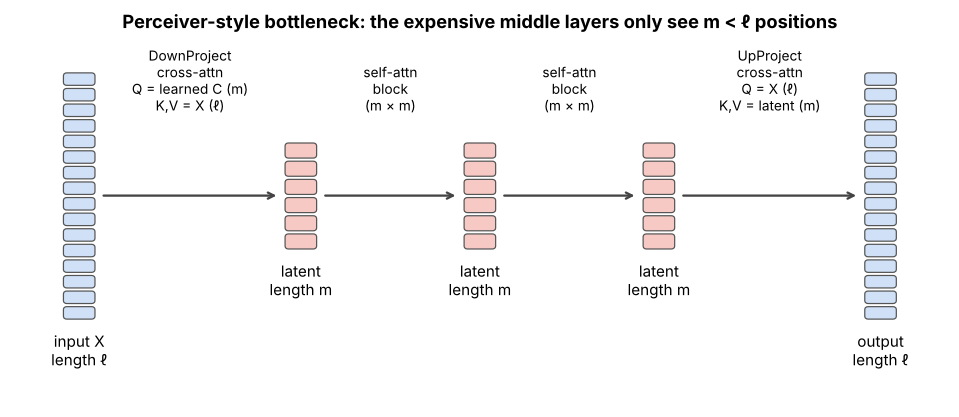

* **DownProjectBlock:** the queries are $m$ **learned** vectors $C \in \mathbb{R}^{m \times d}$; keys/values come from the input $X$:
  $\;Y^{(1)} = \text{softmax}\big((CQ)(XK)^\top/\sqrt{d_h}\big)(XV)\in\mathbb{R}^{m\times d}$
* **UpProjectBlock:** the queries come from the original input $X$ (length $\ell$); keys/values are the latent sequence (length $m$).

Same causal mask as before (row $i$ may see columns $\le i$), so the model still can't see the future.

In [ ]:
class DownProjectBlock(nn.Module):
    def __init__(self, n_embd, n_head, bottleneck_dim, dropout=0.1):
        super().__init__()
        self.C = nn.Parameter(nn.init.xavier_uniform_(torch.empty(1, bottleneck_dim, n_embd)))   # learned queries
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = Attention(n_embd, n_head, dropout)
        self.mlp = mlp(n_embd, dropout)

    def forward(self, x_input):                              # (B, l, d) -> (B, m, d)
        x = self.C + self.attn(self.ln1(self.C), self.ln1(x_input))
        return x + self.mlp(self.ln2(x))

class UpProjectBlock(nn.Module):
    def __init__(self, n_embd, n_head, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = Attention(n_embd, n_head, dropout)
        self.mlp = mlp(n_embd, dropout)

    def forward(self, y, x_input):                           # latent (B, m, d), input (B, l, d) -> (B, l, d)
        x = x_input + self.attn(self.ln1(x_input), self.ln1(y))
        return x + self.mlp(self.ln2(x))

test_model = GPT(bottleneck_dim=64).to(device)
print('output shape:', test_model(torch.zeros(2, BLOCK_SIZE, dtype=torch.long, device=device))[0].shape)   # (2, 128, vocab)

**Cost of the attention scores** (count of query–key pairs per head), with $L$ layers:

| Model | Formula | $\ell=128,\ m=64,\ L=4$ |
|---|---|---|
| Vanilla | $L\,\ell^2$ | 65,536 |
| Perceiver | $\ell m + (L-2)\,m^2 + \ell m$ | 24,576 |

The saving grows quickly for long sequences (it's $\ell^2$ vs. roughly $\ell m$). The price is less capacity:
the assignment only expects about 5% accuracy for this variant (vs. ≥ 10% for vanilla).

Pretrain + finetune it exactly like before (another long run):

In [ ]:
ckpt = 'perceiver_pretrain.pt'
torch.manual_seed(0)
perceiver = GPT(bottleneck_dim=64).to(device)
if os.path.exists(ckpt):
    perceiver.load_state_dict(torch.load(ckpt, map_location=device))
else:
    train(perceiver, pretrain_data, epochs=PRETRAIN_EPOCHS, batch_size=128, lr=6e-3, n_pretrain_docs=N_DOCS, print_every=50)
    torch.save(perceiver.state_dict(), ckpt)
train(perceiver, finetune_data, epochs=10, batch_size=256, lr=6e-4, n_pretrain_docs=N_DOCS, print_every=2)
acc_perceiver = evaluate(perceiver, show=5)

## Takeaways

* **Attention** = softmax-weighted average of values; a large query aligned with one key **copies** its value. **Multiple heads** let a layer gather several things robustly.
* **Scaling** by $\sqrt{d_{head}}$ keeps softmax from saturating; the **causal mask** stops a language model from seeing the future; **position embeddings** give it word order.
* A **Transformer block** = attention + MLP, each with a residual connection and LayerNorm.
* **Without pretraining**, a model can only learn what's in its small task dataset → fails on knowledge questions.
* **Pretraining** (here: span corruption on Wikipedia text) stores knowledge in the weights; **finetuning** teaches the model to retrieve it.
  But retrieved and invented answers look the same, so outputs need care.
* **Perceiver-style cross-attention** to a short latent sequence trades a bit of accuracy for much cheaper attention.